# Customer Segmentation (Sales Data Sample)

Segment customers using K-Means Clustering (Elbow Method) and Hierarchical Clustering (Dendrogram).

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, AgglomerativeClustering
from scipy.cluster.hierarchy import dendrogram, linkage

df = pd.read_csv("/kaggle/input/datasets/kyanyoga/sample-sales-data/sales_data_sample.csv", encoding="latin1")
print("Original dataset shape:", df.shape)
print(df.head())

Original dataset shape: (2823, 25)
   ORDERNUMBER  QUANTITYORDERED  PRICEEACH  ORDERLINENUMBER    SALES  \
0        10107               30      95.70                2  2871.00   
1        10121               34      81.35                5  2765.90   
2        10134               41      94.74                2  3884.34   
3        10145               45      83.26                6  3746.70   
4        10159               49     100.00               14  5205.27   
         ORDERDATE   STATUS  QTR_ID  MONTH_ID  YEAR_ID  ...  \
0   2/24/2003 0:00  Shipped       1         2     2003  ...   
1    5/7/2003 0:00  Shipped       2         5     2003  ...   
2    7/1/2003 0:00  Shipped       3         7     2003  ...   
3   8/25/2003 0:00  Shipped       3         8     2003  ...   
4  10/10/2003 0:00  Shipped       4        10     2003  ...   
                    ADDRESSLINE1  ADDRESSLINE2           CITY STATE  \
0        897 Long Airport Avenue           NaN            NYC    NY   
1            

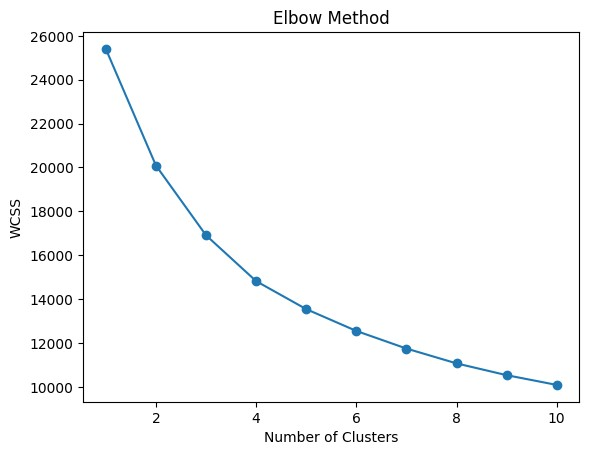

In [ ]:
X = df.select_dtypes(include="number").dropna()
X_scaled = StandardScaler().fit_transform(X)

wcss = []
for k in range(1, 11):
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    kmeans.fit(X_scaled)
    wcss.append(kmeans.inertia_)

plt.plot(range(1, 11), wcss, marker="o")
plt.title("Elbow Method")
plt.xlabel("Number of Clusters")
plt.ylabel("WCSS")
plt.show()

In [ ]:
kmeans = KMeans(n_clusters=3, random_state=42, n_init=10)
df.loc[X.index, "KMeans_Cluster"] = kmeans.fit_predict(X_scaled)
print("K-Means cluster counts:")
print(df["KMeans_Cluster"].value_counts())

K-Means cluster counts:
KMeans_Cluster
1.0    1183
2.0     906
0.0     734
Name: count, dtype: int64



Hierarchical cluster counts:
Hierarchical_Cluster
0.0    1655
1.0     690
2.0     478
Name: count, dtype: int64


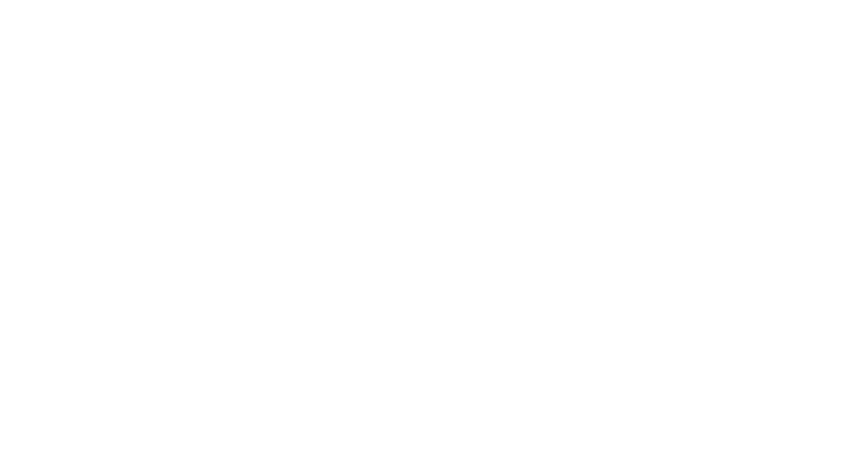

In [ ]:
hierarchical = AgglomerativeClustering(n_clusters=3)
df.loc[X.index, "Hierarchical_Cluster"] = hierarchical.fit_predict(X_scaled)
print("\nHierarchical cluster counts:")
print(df["Hierarchical_Cluster"].value_counts())

sample = X_scaled[:100]
linked = linkage(sample, method="ward")
plt.figure(figsize=(10, 5))
dendrogram(linked)
plt.title("Hierarchical Clustering Dendrogram")
plt.xlabel("Data Points")
plt.ylabel("Distance")
plt.show()